<span style="color: green; font-weight: bold;">
Supervised Machine Learning Algorithms (Linear Regression, Logistic Regression, SVM, Random Forest)
</span>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as snsa
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/thisisebube/ai-job-market-dashboard/main/AI_Job_Market_Trends_2026.csv"

data = pd.read_csv(url)

print(data.shape)
data.head()

(10345, 19)


,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,AI Engineer,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,Machine Learning Engineer,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,Machine Learning Engineer,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,Business Analyst,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,Data Scientist,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2


In [3]:
data_copy = data
data_copy

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,AI Engineer,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,Machine Learning Engineer,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,Machine Learning Engineer,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,Business Analyst,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,Data Scientist,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10340,10341,Data Engineer,Startup,Technology,USA,Onsite,Entry,2,PhD,1,0,1,0,1,76426,4,2023,Low,4
10341,10342,Data Analyst,Medium,Healthcare,Australia,Hybrid,Entry,10,Master,1,1,0,0,1,61233,9,2024,Medium,6
10342,10343,Machine Learning Engineer,Startup,Education,Germany,Hybrid,Entry,4,PhD,0,0,0,1,0,103681,3,2026,Low,4
10343,10344,Data Engineer,MNC,E-commerce,Canada,Hybrid,Mid,5,PhD,1,1,1,0,0,112895,12,2024,High,9


In [4]:
data_copy.dtypes

,0
job_id,int64
job_title,object
company_size,object
company_industry,object
country,object
remote_type,object
experience_level,object
years_experience,int64
education_level,object
skills_python,int64


In [5]:
data_copy.describe()

,job_id,years_experience,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,job_openings
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.00000,10345.000000,10345.000000,10345.00000
mean,5173.000000,6.950507,0.493088,0.503045,0.507878,0.498018,0.511455,113438.22726,6.502465,2023.000387,5.00406
std,2986.488601,4.320054,0.499976,0.500015,0.499962,0.500020,0.499893,31389.20106,3.473441,1.996856,2.58382
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45083.00000,1.000000,2020.000000,1.00000
25%,2587.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,89715.00000,4.000000,2021.000000,3.00000
50%,5173.000000,7.000000,0.000000,1.000000,1.000000,0.000000,1.000000,113082.00000,6.000000,2023.000000,5.00000
75%,7759.000000,11.000000,1.000000,1.000000,1.000000,1.000000,1.000000,134894.00000,10.000000,2025.000000,7.00000
max,10345.000000,14.000000,1.000000,1.000000,1.000000,1.000000,1.000000,204143.00000,12.000000,2026.000000,9.00000


In [6]:
data_copy.shape

(10345, 19)

In [7]:
 data.isnull().sum()

,0
job_id,0
job_title,0
company_size,0
company_industry,0
country,0
remote_type,0
experience_level,0
years_experience,0
education_level,0
skills_python,0


In [8]:
data_copy.duplicated().sum()

np.int64(0)

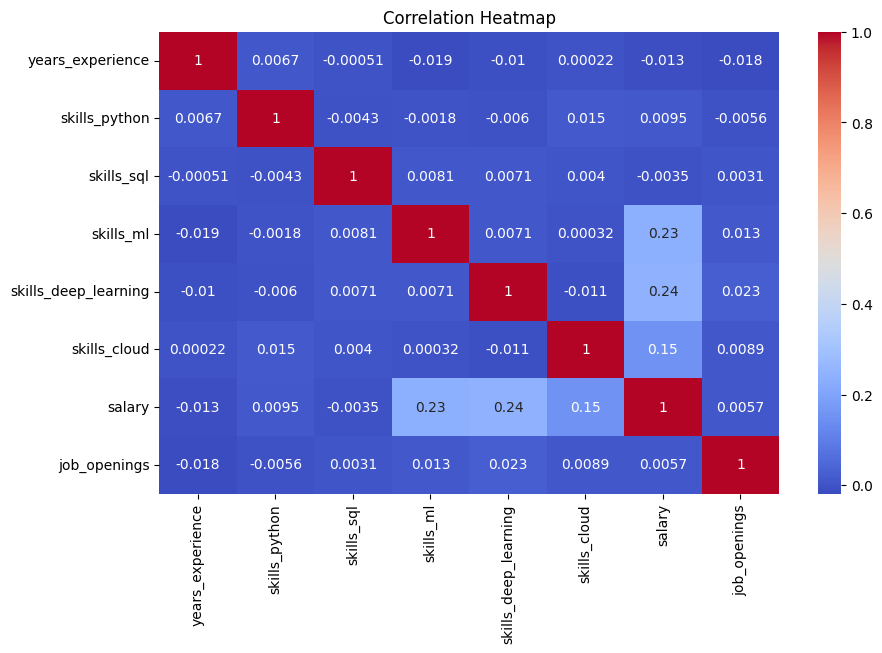

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = [
    'years_experience', 'skills_python', 'skills_sql',
    'skills_ml', 'skills_deep_learning', 'skills_cloud',
    'salary', 'job_openings'
]

plt.figure(figsize=(10,6))
sns.heatmap(data[numeric_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

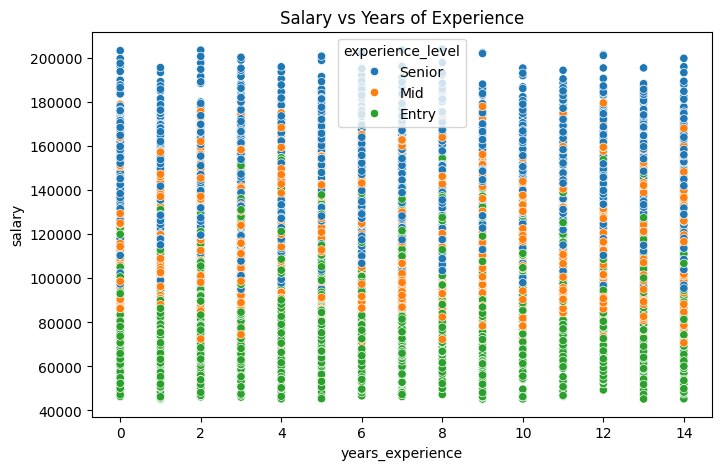

In [11]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='years_experience', y='salary', data=data, hue='experience_level')
plt.title("Salary vs Years of Experience")
plt.show()

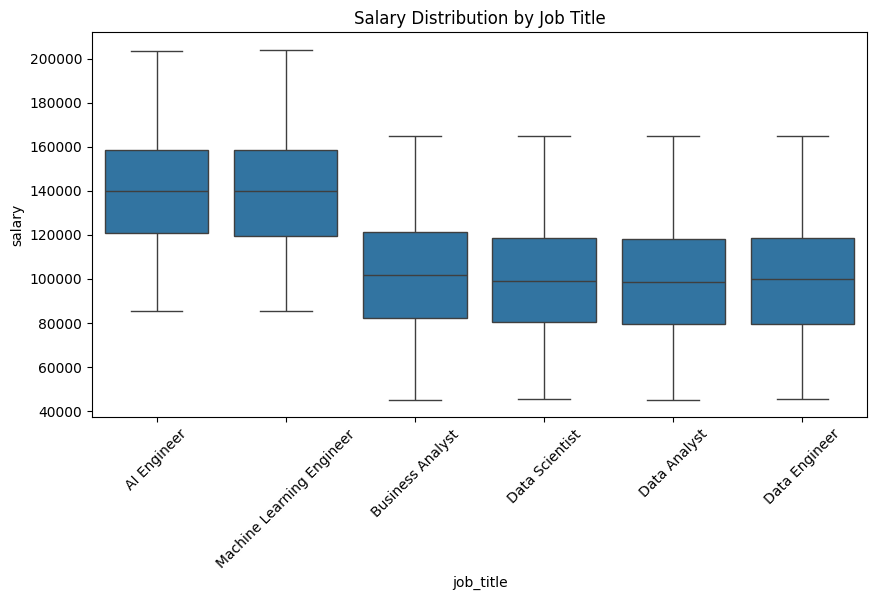

In [12]:
plt.figure(figsize=(10,5))
sns.boxplot(x='job_title', y='salary', data=data)
plt.xticks(rotation=45)
plt.title("Salary Distribution by Job Title")
plt.show()

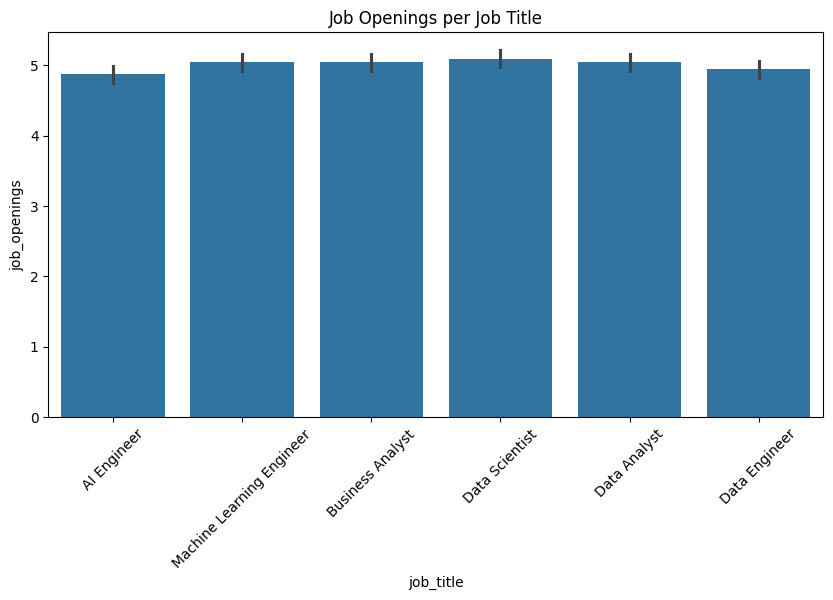

In [13]:
plt.figure(figsize=(10,5))
sns.barplot(x='job_title', y='job_openings', data=data_copy)
plt.xticks(rotation=45)
plt.title("Job Openings per Job Title")
plt.show()

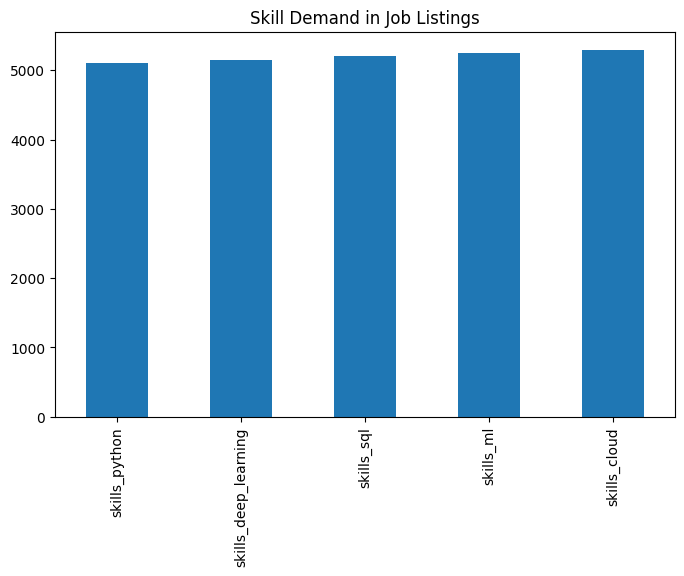

In [14]:
skill_cols = ['skills_python','skills_sql','skills_ml','skills_deep_learning','skills_cloud']

skill_sum = data_copy[skill_cols].sum().sort_values()

plt.figure(figsize=(8,5))
skill_sum.plot(kind='bar')
plt.title("Skill Demand in Job Listings")
plt.show()

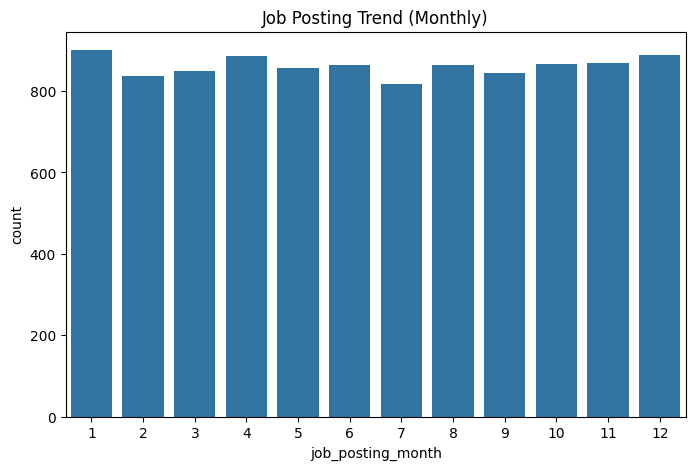

In [15]:
plt.figure(figsize=(8,5))
sns.countplot(x='job_posting_month', data=data_copy)
plt.title("Job Posting Trend (Monthly)")
plt.show()

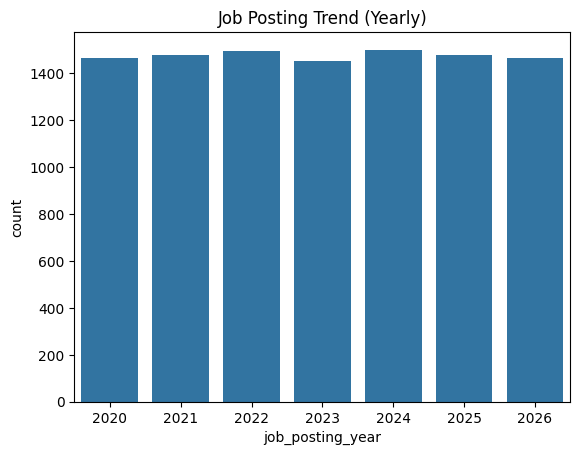

In [16]:
sns.countplot(x='job_posting_year', data=data_copy)
plt.title("Job Posting Trend (Yearly)")
plt.show()

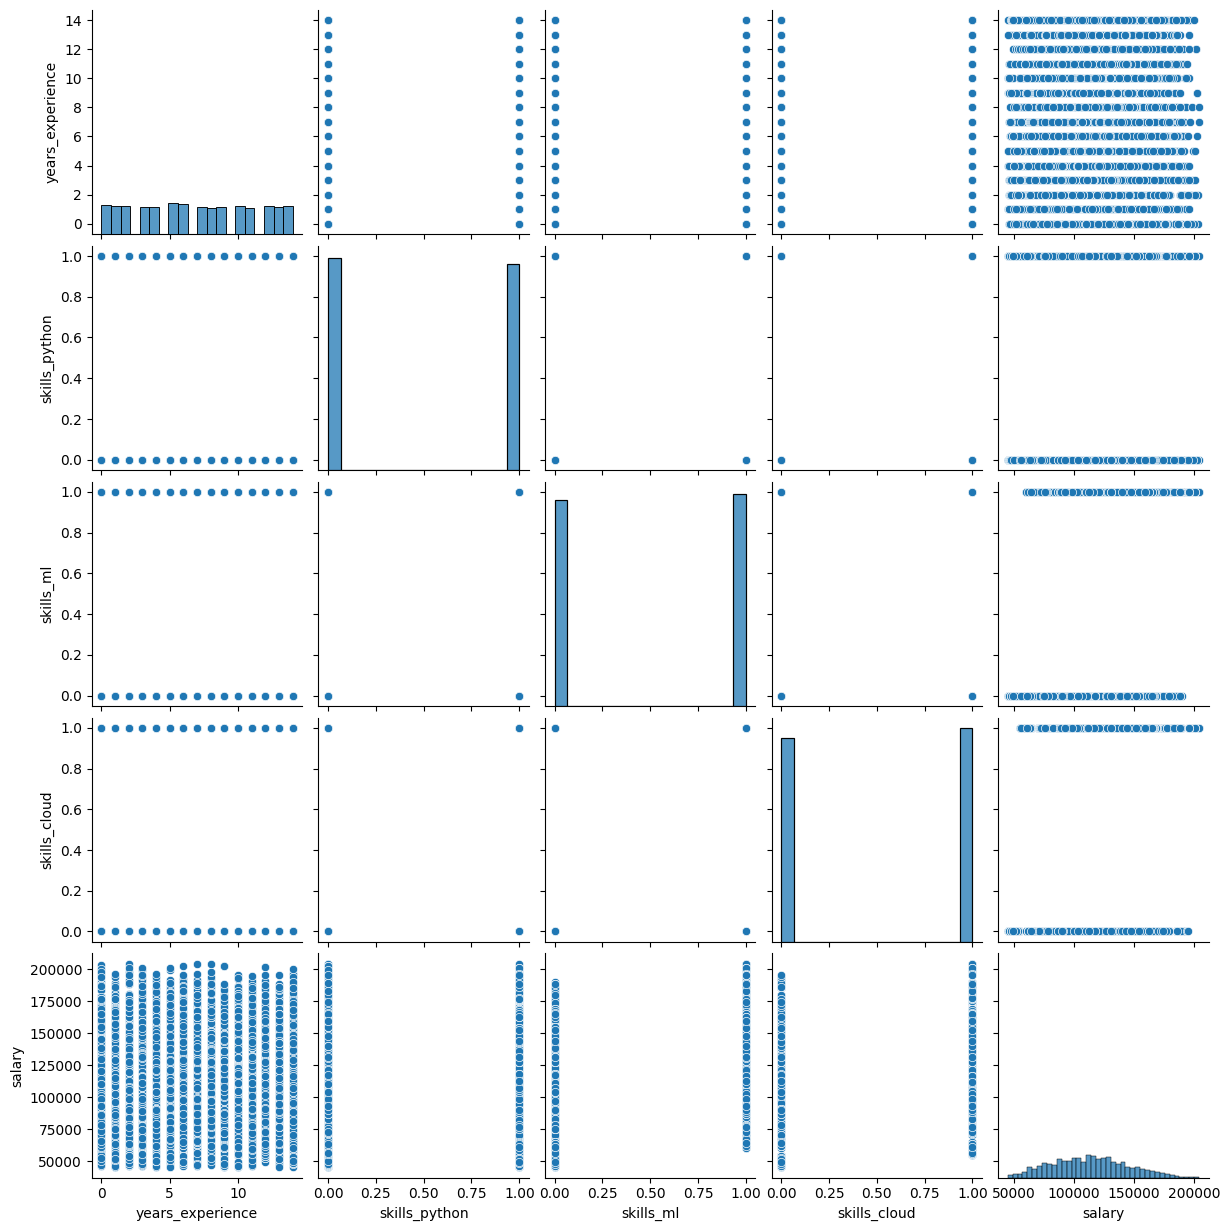

In [17]:
sns.pairplot(data_copy[['years_experience','skills_python','skills_ml','skills_cloud','salary']])
plt.show()

In [18]:
data_copy.columns

Index(['job_id', 'job_title', 'company_size', 'company_industry', 'country',
       'remote_type', 'experience_level', 'years_experience',
       'education_level', 'skills_python', 'skills_sql', 'skills_ml',
       'skills_deep_learning', 'skills_cloud', 'salary', 'job_posting_month',
       'job_posting_year', 'hiring_urgency', 'job_openings'],
      dtype='object')

In [19]:
data_copy['job_title'].unique()

array(['AI Engineer', 'Machine Learning Engineer', 'Business Analyst',
       'Data Scientist', 'Data Analyst', 'Data Engineer'], dtype=object)

In [20]:
data_copy['company_size'].unique()

array(['Startup', 'MNC', 'Medium', 'Enterprise'], dtype=object)

In [21]:
data_copy['company_industry'].unique()

array(['Retail', 'Technology', 'Healthcare', 'Finance', 'Education',
       'E-commerce'], dtype=object)

In [22]:
data_copy['country'].nunique()

7

In [23]:
data_copy['remote_type'].unique()

array(['Remote', 'Hybrid', 'Onsite'], dtype=object)

In [24]:
data_copy['experience_level'].unique()

array(['Senior', 'Mid', 'Entry'], dtype=object)

In [25]:
data_copy['years_experience'].unique()

array([ 2,  0, 14,  9,  5,  6,  4, 10, 13,  3, 12, 11,  8,  1,  7])

In [26]:
data_copy['education_level'].unique()

array(['Master', 'Bachelor', 'PhD'], dtype=object)

In [27]:
data_copy['job_openings'].unique()

array([4, 9, 7, 2, 8, 3, 5, 6, 1])

In [28]:
data_copy['hiring_urgency'].unique()

array(['Low', 'High', 'Medium'], dtype=object)

In [29]:
data_copy['job_title'] = (
    data_copy['job_title']
    .replace({
        'AI Engineer': 0,
        'Machine Learning Engineer': 1,
        'Business Analyst': 2,
        'Data Scientist': 3,
        'Data Analyst': 4,
        'Data Engineer': 5
    })
    .infer_objects(copy=False)
    .astype(int)
)

/tmp/ipykernel_4637/3172993482.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({


In [30]:
data_copy

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,0,Startup,Retail,Canada,Remote,Senior,2,Master,0,0,0,1,0,158322,6,2024,Low,4
1,2,1,MNC,Technology,Australia,Hybrid,Mid,0,Bachelor,1,1,1,0,1,163666,11,2026,High,9
2,3,1,MNC,Technology,Germany,Onsite,Mid,14,Master,1,0,1,0,1,158556,3,2026,High,9
3,4,2,Startup,Healthcare,Germany,Remote,Mid,9,Master,0,1,0,1,1,95775,3,2025,High,7
4,5,3,MNC,Healthcare,Germany,Hybrid,Mid,5,Master,1,1,1,0,0,111873,12,2021,Low,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10340,10341,5,Startup,Technology,USA,Onsite,Entry,2,PhD,1,0,1,0,1,76426,4,2023,Low,4
10341,10342,4,Medium,Healthcare,Australia,Hybrid,Entry,10,Master,1,1,0,0,1,61233,9,2024,Medium,6
10342,10343,1,Startup,Education,Germany,Hybrid,Entry,4,PhD,0,0,0,1,0,103681,3,2026,Low,4
10343,10344,5,MNC,E-commerce,Canada,Hybrid,Mid,5,PhD,1,1,1,0,0,112895,12,2024,High,9


In [31]:
data_copy['company_size'] = data_copy['company_size'].replace({
    'Startup': 0,
    'MNC': 1,
    'Medium': 2,
    'Enterprise': 3,

}) .infer_objects(copy=False).astype(int)

/tmp/ipykernel_4637/349207617.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_copy['company_size'] = data_copy['company_size'].replace({


In [32]:
data_copy['experience_level'] = (
    data_copy['experience_level']
    .replace({
        'Senior': 0,
        'Mid': 1,
        'Entry': 2
    })
    .infer_objects(copy=False)
    .astype(int)
)

/tmp/ipykernel_4637/1967821808.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({


In [33]:
data_copy['education_level'] = (
    data_copy['education_level']
    .replace({
        'Master': 0,
        'Bachelor': 1,
        'PhD': 2
    })
    .infer_objects(copy=False)
    .astype(int)
)

/tmp/ipykernel_4637/1659935659.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({


In [34]:
data_copy['education_level'].unique()

array([0, 1, 2])

In [35]:
data_copy

,job_id,job_title,company_size,company_industry,country,remote_type,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,1,0,0,Retail,Canada,Remote,0,2,0,0,0,0,1,0,158322,6,2024,Low,4
1,2,1,1,Technology,Australia,Hybrid,1,0,1,1,1,1,0,1,163666,11,2026,High,9
2,3,1,1,Technology,Germany,Onsite,1,14,0,1,0,1,0,1,158556,3,2026,High,9
3,4,2,0,Healthcare,Germany,Remote,1,9,0,0,1,0,1,1,95775,3,2025,High,7
4,5,3,1,Healthcare,Germany,Hybrid,1,5,0,1,1,1,0,0,111873,12,2021,Low,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10340,10341,5,0,Technology,USA,Onsite,2,2,2,1,0,1,0,1,76426,4,2023,Low,4
10341,10342,4,2,Healthcare,Australia,Hybrid,2,10,0,1,1,0,0,1,61233,9,2024,Medium,6
10342,10343,1,0,Education,Germany,Hybrid,2,4,2,0,0,0,1,0,103681,3,2026,Low,4
10343,10344,5,1,E-commerce,Canada,Hybrid,1,5,2,1,1,1,0,0,112895,12,2024,High,9


In [36]:
data_copy.describe()

,job_id,job_title,company_size,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,job_openings
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.00000,10345.000000,10345.000000,10345.00000
mean,5173.000000,2.476462,1.482165,1.008990,6.950507,0.989947,0.493088,0.503045,0.507878,0.498018,0.511455,113438.22726,6.502465,2023.000387,5.00406
std,2986.488601,1.702738,1.120666,0.818635,4.320054,0.819861,0.499976,0.500015,0.499962,0.500020,0.499893,31389.20106,3.473441,1.996856,2.58382
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45083.00000,1.000000,2020.000000,1.00000
25%,2587.000000,1.000000,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,89715.00000,4.000000,2021.000000,3.00000
50%,5173.000000,2.000000,1.000000,1.000000,7.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,113082.00000,6.000000,2023.000000,5.00000
75%,7759.000000,4.000000,2.000000,2.000000,11.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,134894.00000,10.000000,2025.000000,7.00000
max,10345.000000,5.000000,3.000000,2.000000,14.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,204143.00000,12.000000,2026.000000,9.00000


In [37]:
data_copy.isna().sum()

,0
job_id,0
job_title,0
company_size,0
company_industry,0
country,0
remote_type,0
experience_level,0
years_experience,0
education_level,0
skills_python,0


In [38]:
data_copy.describe().columns

Index(['job_id', 'job_title', 'company_size', 'experience_level',
       'years_experience', 'education_level', 'skills_python', 'skills_sql',
       'skills_ml', 'skills_deep_learning', 'skills_cloud', 'salary',
       'job_posting_month', 'job_posting_year', 'job_openings'],
      dtype='object')

<span style="color: red; font-weight: bold;">LINEAR REGRESSION (salary)</span>

In [39]:
feature_cols = [
    'job_title', 'company_size', 'experience_level',
       'years_experience', 'education_level', 'skills_python', 'skills_sql',
       'skills_ml', 'skills_deep_learning', 'skills_cloud',
       'job_posting_month', 'job_posting_year', 'job_openings'
]

X = data_copy[feature_cols]
y = data_copy['salary']

In [40]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [41]:
scaler = StandardScaler()
X_trains = scaler.fit_transform(X_train)
X_tests = scaler.transform(X_test)

In [42]:
model = LinearRegression()
model.fit(X_trains, y_train)

LinearRegression()

In [43]:
y_pred = model.predict(X_tests)

In [44]:
print("R2 Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

R2 Score: 0.8065183499395752
MSE: 192648811.74556717


In [45]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

pipeline.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())])

In [46]:
new_data = {
    'job_title': 3,
    'company_size': 2,
    'experience_level': 1,
    'years_experience': 4,
    'education_level': 2,
    'skills_python': 1,
    'skills_sql': 1,
    'skills_ml': 1,
    'skills_deep_learning': 0,
    'skills_cloud': 1,
    'job_posting_month': 5,
    'job_posting_year': 2024,
    'job_openings': 3
}

In [47]:
new_df = pd.DataFrame([new_data], columns=feature_cols)

In [48]:
predicted_salary = pipeline.predict(new_df)[0]
print("Predicted Salary:", predicted_salary)

Predicted Salary: 112688.83003668657


<span style="color: red; font-weight: bold;">Logistic REGRESSION (Hiring Urgency)</span>

In [49]:
data_copy['hiring_urgency'] = data_copy['hiring_urgency'].replace({
    'Low': 0,
    'Medium': 0,
    'High': 2
}).astype(int)

/tmp/ipykernel_4637/3810086881.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data_copy['hiring_urgency'] = data_copy['hiring_urgency'].replace({


In [50]:
feature_cols = [
    'job_title', 'company_size', 'experience_level',
    'years_experience', 'education_level', 'skills_python', 'skills_sql',
    'skills_ml', 'skills_deep_learning', 'skills_cloud',
    'job_posting_month', 'job_posting_year', 'job_openings'
]

X = data_copy[feature_cols]
y = data_copy['hiring_urgency']

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [52]:
from sklearn.linear_model import LogisticRegression

logit_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression())
])

In [53]:
model = LogisticRegression()
model.fit(X_trains, y_train)

LogisticRegression()

In [54]:
logit_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('logit', LogisticRegression())])

In [55]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = logit_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8443692605123247

Confusion Matrix:
 [[863 179]
 [143 884]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.83      0.84      1042
           2       0.83      0.86      0.85      1027

    accuracy                           0.84      2069
   macro avg       0.84      0.84      0.84      2069
weighted avg       0.84      0.84      0.84      2069



In [56]:
new_data = {
    'job_title': 3,
    'company_size': 2,
    'experience_level': 1,
    'years_experience': 4,
    'education_level': 2,
    'skills_python': 1,
    'skills_sql': 1,
    'skills_ml': 1,
    'skills_deep_learning': 0,
    'skills_cloud': 1,
    'job_posting_month': 5,
    'job_posting_year': 2024,
    'job_openings': 3
}

new_df = pd.DataFrame([new_data], columns=feature_cols)

prediction = logit_model.predict(new_df)[0]
probability = logit_model.predict_proba(new_df)[0][1]

print("Predicted (1=Urgent, 0=Not urgent):", prediction)
print("Urgency Probability:", probability)

Predicted (1=Urgent, 0=Not urgent): 0
Urgency Probability: 0.104287423843774


<span style="color: red; font-weight: bold;">Random Forest</span>

In [58]:
feature_cols = [
    'job_title', 'company_size', 'experience_level',
    'years_experience', 'education_level', 'skills_python', 'skills_sql',
    'skills_ml', 'skills_deep_learning', 'skills_cloud',
    'job_posting_month', 'job_posting_year', 'job_openings'
]

X = data_copy[feature_cols]
y = data_copy['hiring_urgency']

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [60]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, n_estimators=200, random_state=42)

In [61]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 1.0

Confusion Matrix:
 [[1042    0]
 [   0 1027]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1042
           2       1.00      1.00      1.00      1027

    accuracy                           1.00      2069
   macro avg       1.00      1.00      1.00      2069
weighted avg       1.00      1.00      1.00      2069



<span style="color: red; font-weight: bold;">Support Vector Machine</span>

In [62]:
feature_cols = [
    'job_title', 'company_size', 'experience_level',
    'years_experience', 'education_level', 'skills_python', 'skills_sql',
    'skills_ml', 'skills_deep_learning', 'skills_cloud',
    'job_posting_month', 'job_posting_year', 'job_openings'
]

X = data_copy[feature_cols]
y = data_copy['hiring_urgency']

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [64]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [66]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train_scaled, y_train)

SVC(kernel='linear', random_state=42)

In [67]:
y_pred = svm_model.predict(X_test_scaled)

In [68]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8458192363460609
              precision    recall  f1-score   support

           0       0.85      0.84      0.85      1042
           2       0.84      0.85      0.85      1027

    accuracy                           0.85      2069
   macro avg       0.85      0.85      0.85      2069
weighted avg       0.85      0.85      0.85      2069



In [69]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[879 163]
 [156 871]]


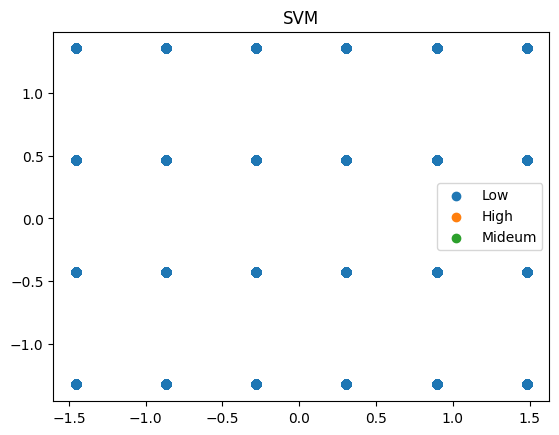

In [70]:
X_vis = X.iloc[:, :2].values
y_vis = y.values
Scaler2 = StandardScaler()
X_vis_Scaled = Scaler2.fit_transform(X_vis)
SVM_vis =SVC(kernel='linear')
SVM_vis.fit(X_vis_Scaled,y_vis)
plt.scatter(X_vis_Scaled[y_vis ==0][:,0],X_vis_Scaled[y_vis==0][0:,1],label='Low')
plt.scatter(X_vis_Scaled[y_vis ==1][:,0],X_vis_Scaled[y_vis==1][0:,1],label='High')
plt.scatter(X_vis_Scaled[y_vis ==1][:,0],X_vis_Scaled[y_vis==1][0:,1],label='Mideum')

plt.legend()
plt.title("SVM")
plt.show()

In [71]:
# Select best features for SVM
svm_features = [
    'years_experience',
    'skills_python',
    'skills_sql',
    'skills_ml',
    'skills_deep_learning',
    'skills_cloud',
    'job_openings',
    'job_posting_month',
    'job_posting_year'
]

# X = input features
X = data_copy[svm_features]

# y = target variable
y = data_copy['hiring_urgency']

In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [73]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [74]:
svm_model = SVC(kernel='linear')  # linear kernel for multiclass
svm_model.fit(X_train_scaled, y_train)

SVC(kernel='linear')

In [75]:
y_pred_svm = svm_model.predict(X_test_scaled)


In [76]:
print("SVM Accuracy:", accuracy_score(y_test, y_pred_svm))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_svm))
print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred_svm))

SVM Accuracy: 0.8482358627356211

Classification Report:

              precision    recall  f1-score   support

           0       0.84      0.86      0.85      1030
           2       0.86      0.83      0.85      1039

    accuracy                           0.85      2069
   macro avg       0.85      0.85      0.85      2069
weighted avg       0.85      0.85      0.85      2069


Confusion Matrix:

[[890 140]
 [174 865]]


<span style="color: green; font-weight: bold;">
Unsupervised Machine Learning Algorithms (K-Means Clusters)
</span>

In [78]:
from sklearn.cluster import KMeans

In [79]:
data_copy.describe().columns

Index(['job_id', 'job_title', 'company_size', 'experience_level',
       'years_experience', 'education_level', 'skills_python', 'skills_sql',
       'skills_ml', 'skills_deep_learning', 'skills_cloud', 'salary',
       'job_posting_month', 'job_posting_year', 'hiring_urgency',
       'job_openings'],
      dtype='object')

In [80]:
X = data_copy[['job_title', 'company_size', 'experience_level',
       'years_experience', 'education_level', 'skills_python', 'skills_sql',
       'skills_ml', 'skills_deep_learning', 'skills_cloud', 'salary',
       'job_posting_month', 'job_posting_year', 'hiring_urgency',
       'job_openings']]
X

,job_title,company_size,experience_level,years_experience,education_level,skills_python,skills_sql,skills_ml,skills_deep_learning,skills_cloud,salary,job_posting_month,job_posting_year,hiring_urgency,job_openings
0,0,0,0,2,0,0,0,0,1,0,158322,6,2024,0,4
1,1,1,1,0,1,1,1,1,0,1,163666,11,2026,2,9
2,1,1,1,14,0,1,0,1,0,1,158556,3,2026,2,9
3,2,0,1,9,0,0,1,0,1,1,95775,3,2025,2,7
4,3,1,1,5,0,1,1,1,0,0,111873,12,2021,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10340,5,0,2,2,2,1,0,1,0,1,76426,4,2023,0,4
10341,4,2,2,10,0,1,1,0,0,1,61233,9,2024,0,6
10342,1,0,2,4,2,0,0,0,1,0,103681,3,2026,0,4
10343,5,1,1,5,2,1,1,1,0,0,112895,12,2024,2,9


In [81]:
kmeans = KMeans(n_clusters=3, random_state=42)
data_copy['cluster'] = kmeans.fit_predict(X)

In [82]:
labels = kmeans.labels_

In [83]:
data_copy["cluster"] = labels
print(data_copy)

       job_id  job_title  company_size company_industry    country  \
0           1          0             0           Retail     Canada   
1           2          1             1       Technology  Australia   
2           3          1             1       Technology    Germany   
3           4          2             0       Healthcare    Germany   
4           5          3             1       Healthcare    Germany   
...       ...        ...           ...              ...        ...   
10340   10341          5             0       Technology        USA   
10341   10342          4             2       Healthcare  Australia   
10342   10343          1             0        Education    Germany   
10343   10344          5             1       E-commerce     Canada   
10344   10345          0             0        Education  Australia   

      remote_type  experience_level  years_experience  education_level  \
0          Remote                 0                 2                0   
1          

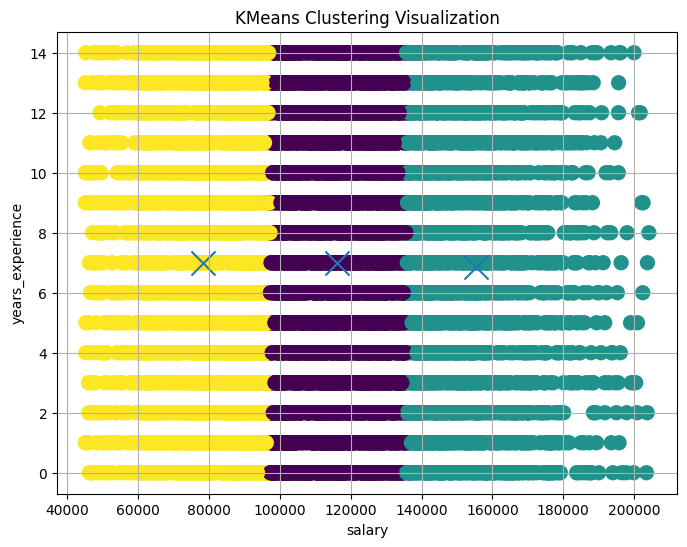

In [84]:
import matplotlib.pyplot as plt


x_col = 'salary'
y_col = 'years_experience'

plt.figure(figsize=(8,6))


plt.scatter(
    data_copy[x_col],
    data_copy[y_col],
    c=data_copy['cluster'],
    s=100
)


feature_names = X.columns.tolist()


i_x = feature_names.index(x_col)
i_y = feature_names.index(y_col)


centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, i_x],
    centers[:, i_y],
    marker='x',
    s=300
)


plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title('KMeans Clustering Visualization')
plt.grid(True)
plt.show()